In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Mean, Variance, Standard Deviation

In [13]:
# Vectorized

N = 1000
x = np.random.uniform(-1, 1, size = N)
xm = np.mean(x)
xv = np.var(x)
xs = np.std(x)
print('%10d mean: %12.5e stdev: %12.5e var: %12.5e' % (N, xm, xs, xv))

      1000 mean:  8.99248e-03 stdev:  5.81194e-01 var:  3.37787e-01


In [14]:
# Old school way - extremely slow

N = 100
sm = 0
sv = 0

for i in range(1, N+1):
    x = np.random.uniform(-1, 1)
    sm += x
    sv += x**2

    # Print out mu and sigma 10 times
    if i % (N/10) == 0:
        xm = sm / i
        xs = np.sqrt(sv / i - xm**2)
        print('%10d mean: %12.5e stdev: %12.5e' % (i, xm, xs))

        10 mean: -2.22390e-01 stdev:  6.12857e-01
        20 mean: -1.57569e-02 stdev:  6.21001e-01
        30 mean: -1.73625e-02 stdev:  5.72075e-01
        40 mean: -3.08992e-02 stdev:  5.62282e-01
        50 mean:  2.87659e-02 stdev:  5.55460e-01
        60 mean:  4.05459e-02 stdev:  5.66424e-01
        70 mean:  7.29781e-02 stdev:  5.68223e-01
        80 mean:  8.52178e-02 stdev:  5.48496e-01
        90 mean:  8.52271e-02 stdev:  5.53264e-01
       100 mean:  9.60685e-02 stdev:  5.58873e-01


Notes: as N gets larger, the mean starts to approach 0. The theoretical value of sigma (standard deviation) as $N \to 0$ is $\sqrt{1 / 3} \approx 0.57735$ 

# Several Ways to Produce and Visualize Random Numbers

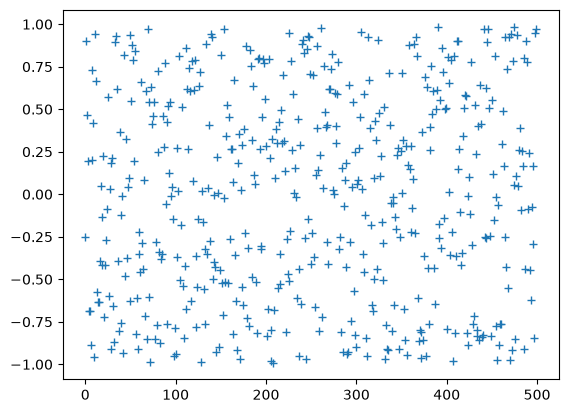

In [25]:
# Visualize random numbers - compare to linear congruent generator method

np.random.seed(42)                         # seeding ensures you get the same result each time
N = 500                                    # number of samples
x = range(N)                               # x-axis
y = [np.random.uniform(-1,1) for i in x]   # random number generation

plt.plot(x, y, '+')

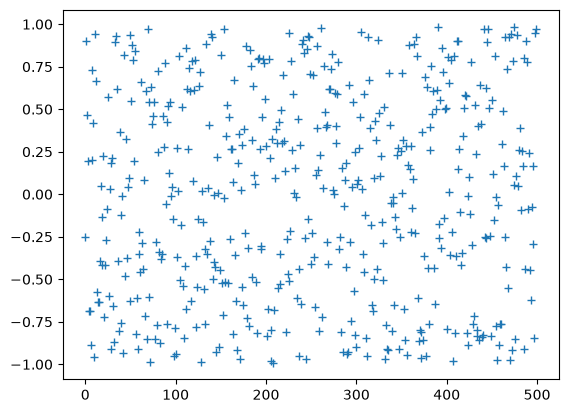

In [19]:
# Visualize random numbers - quicker

np.random.seed(42)                                # seeding ensures you get the same result each time
N = 500                                           # I could also set x = range(N) and then the in the loop [for i in x]
y = [np.random.uniform(-1,1) for i in range(N)]   # random number generation

plt.plot(y, '+')

(array([ 93.,  93., 114.,  85., 104., 111., 110., 102., 104.,  84.]),
 array([5.56358476e-04, 1.00470303e-01, 2.00384247e-01, 3.00298191e-01,
        4.00212136e-01, 5.00126080e-01, 6.00040024e-01, 6.99953968e-01,
        7.99867913e-01, 8.99781857e-01, 9.99695801e-01]),
 <BarContainer object of 10 artists>)

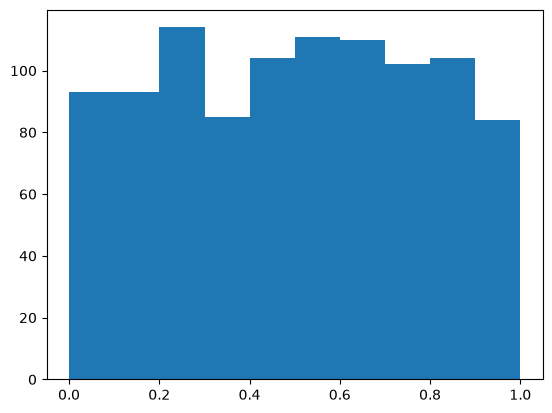

In [21]:
# How to plot a histogram of a uniform distribution

samples = [random.random() for i in range(1000)]
plt.hist(samples)

(array([ 10.,  26.,  93., 174., 223., 226., 138.,  80.,  23.,   7.]),
 array([-22.40638445,  -7.46854399,   7.46929648,  22.40713695,
         37.34497741,  52.28281788,  67.22065834,  82.15849881,
         97.09633928, 112.03417974, 126.97202021]),
 <BarContainer object of 10 artists>)

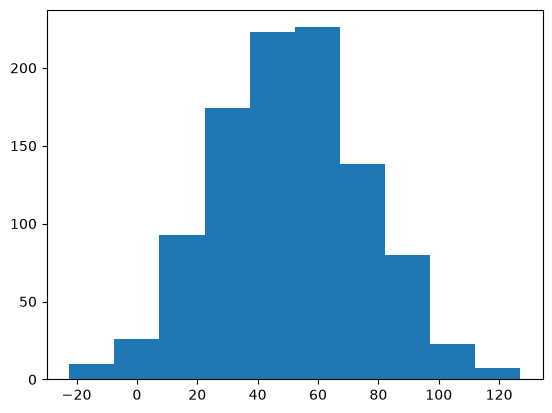

In [22]:
# And a normal (Gaussian) distribution:

x = np.random.normal(50, 25, 1000)          # Mean, Std Deviation, Size
plt.hist(x)

The next few cells highlight how seed() works.

In [16]:
import random

random.seed(2)
['%.2f' % random.random() for i in range(10)]

['0.96',
 '0.95',
 '0.06',
 '0.08',
 '0.84',
 '0.74',
 '0.67',
 '0.31',
 '0.61',
 '0.61']

In [17]:
['%.2f' % random.random() for i in range(10)]

['0.58',
 '0.16',
 '0.43',
 '0.39',
 '0.72',
 '0.99',
 '0.95',
 '0.54',
 '0.44',
 '0.27']

In [18]:
random.seed(2)
['%.2f' % random.random() for i in range(10)]

['0.96',
 '0.95',
 '0.06',
 '0.08',
 '0.84',
 '0.74',
 '0.67',
 '0.31',
 '0.61',
 '0.61']

In [23]:
# using numpy, you select the range of numbers then how many you want
# no loops
samples_np = np.random.uniform(-1, 1, size=1000)
# or just one time
rand_np = np.random.uniform(-1,1)
rand_int = np.random.randint(0, N)
print(rand_int)
print(rand_np)
#print(samples_np)

# note = np.random.randint(a, b, N) does not include b, have to use np.random.randint(a, b+1, N)
# however, np.random.random_integers(a, b, N) does include b

271
0.9212539510263995


Thinking out loud: my main loop needs to have an if where it compares the probability (of moving boxes) to a random number. \
\
if np.random.randint(0, N) > (n / N): \
    change state from 0 to 1 \
\
So - how this all work when checking both sides? The particle chosen is obviously the array, particles[i]... \
\
so maybe, if i = 0, then use n / N as the probability \
\
and if i = 1 then use (N - n) / N as the probability to compare to. \
